# Anexo. Ablación y análisis de errores (XGBoost)

Responde dos preguntas sobre el XGBoost de `03_xgboost.ipynb` (mismo conjunto de prueba de Lima, mismos hiperparámetros, 3 semillas, `N_JOBS=1`):

1. **Ablación:** ¿qué grupo de variables aporta más?
2. **Errores:** ¿en qué fase de la ola se equivoca el modelo?

In [1]:
import sys
sys.path.insert(0, "../src")
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from evaluation import PERCENTIL_BROTE, a_casos, mae, prueba_lima
from models import SEMILLAS, walk_forward
from preprocessing import (CASOS, CLIMA_COLS, DEPARTAMENTOS_MODELO, EXT, FEATURES, NUEVAS,
                           PROCESSED, REG, preparar)

RESULTS = Path("../results")
mejores = json.loads((RESULTS / "tuning_hiperparametros.json").read_text())
ref = prueba_lima(pd.read_csv(PROCESSED / "modelado.csv", parse_dates=["fecha_inicio"]))
m = preparar(DEPARTAMENTOS_MODELO)
lima = m[m.departamento == "LIMA"]
test_idx = lima.index[lima.fecha_inicio.isin(ref.fecha_inicio)]
prueba = m.loc[test_idx].reset_index(drop=True)
fechas = pd.DatetimeIndex(prueba["fecha_inicio"])
real = a_casos(prueba["objetivo"].to_numpy())
pers = a_casos(prueba["log_casos"].to_numpy())
umbral = np.percentile(real, PERCENTIL_BROTE)
print(len(prueba), "semanas | umbral brote:", round(umbral))

759 semanas | umbral brote: 55


## 1. Ablación

Se parte del modelo completo (base + regional + nuevas) y se quita un grupo cada vez; también se agrega cada grupo a la base. El MAE se reporta en casos, medio de 3 semillas.

Grupos de la base: **clima** (actual y rezagado), **casos** (rezagos del historial), **ICEN**, **estacionalidad** (seno y coseno de la semana).

In [2]:
CLIMA = CLIMA_COLS + EXT
ICEN, ESTAC = ["icen"], ["sem_sin", "sem_cos"]
COMPLETO = FEATURES + REG + NUEVAS
def sin(*grupos):
    quitar = {c for g in grupos for c in g}
    return [c for c in COMPLETO if c not in quitar]

variantes = {
    "Completo (base + regional + nuevas)": COMPLETO,
    "Solo base": FEATURES,
    "Base + regional": FEATURES + REG,
    "Base + nuevas": FEATURES + NUEVAS,
    "Completo sin ICEN": sin(ICEN),
    "Completo sin estacionalidad": sin(ESTAC),
    "Completo sin clima": sin(CLIMA),
    "Completo sin regional": sin(REG),
    "Completo sin nuevas": sin(NUEVAS),
}
preds_ab = {n: np.mean([a_casos(walk_forward(m, test_idx, mejores, s, cols)) for s in SEMILLAS], axis=0)
            for n, cols in variantes.items()}
m23, m24 = fechas >= "2023-01-01", fechas >= "2024-01-01"
def fila(p):
    return {"MAE": mae(real, p), "MAE 2023-24": mae(real[m23], p[m23]), "MAE 2024": mae(real[m24], p[m24])}
ab = pd.DataFrame({n: fila(p) for n, p in preds_ab.items()}).T
ab.loc["Persistencia"] = fila(pers)
ab["cambio vs completo %"] = (ab["MAE"] / ab.loc["Completo (base + regional + nuevas)", "MAE"] - 1) * 100
ab.round(1).to_csv(RESULTS / "ablacion.csv")
print(ab.round(1).to_string())

                                       MAE  MAE 2023-24  MAE 2024  cambio vs completo %
Completo (base + regional + nuevas)   66.4        497.3     793.4                   0.0
Solo base                             77.5        584.2     968.6                  16.8
Base + regional                       70.6        530.5     830.3                   6.4
Base + nuevas                         69.5        521.6     839.6                   4.7
Completo sin ICEN                     69.2        520.4     811.0                   4.3
Completo sin estacionalidad           77.5        584.8     937.4                  16.8
Completo sin clima                    70.9        532.3     802.5                   6.8
Completo sin regional                 69.5        521.6     839.6                   4.7
Completo sin nuevas                   70.6        530.5     830.3                   6.4
Persistencia                         132.8       1014.5    1688.2                 100.1


## 2. Errores por fase de la ola

In [3]:
# Fase según el cambio REAL a 4 semanas (log): subida > +0.2, bajada < -0.2, estable el resto.
d = np.log1p(real) - np.log1p(pers)
fase = np.where(d > 0.2, "subida", np.where(d < -0.2, "bajada", "estable"))
brote = real >= umbral
completo = preds_ab["Completo (base + regional + nuevas)"]
base = preds_ab["Solo base"]
filas = []
for nombre, mask in [("subida", fase == "subida"), ("bajada", fase == "bajada"), ("estable", fase == "estable"),
                     ("semanas de brote (p90)", brote), ("resto", ~brote)]:
    fila_ = {"fase": nombre, "semanas": int(mask.sum())}
    for n, p in [("Persistencia", pers), ("Solo base", base), ("Completo", completo)]:
        fila_[f"MAE {n}"] = np.abs(real - p)[mask].mean()
        fila_[f"% error total {n}"] = np.abs(real - p)[mask].sum() / np.abs(real - p).sum() * 100
    filas.append(fila_)
fases = pd.DataFrame(filas).set_index("fase")
fases.round(1).to_csv(RESULTS / "error_por_fase.csv")
print(fases.round(1).T.to_string())

fase                        subida  bajada  estable  semanas de brote (p90)  resto
semanas                      155.0   183.0    421.0                    77.0  682.0
MAE Persistencia             323.6   269.7      3.0                  1266.1    4.8
% error total Persistencia    49.8    49.0      1.2                    96.8    3.2
MAE Solo base                227.8    89.5     17.0                   741.9    2.5
% error total Solo base       60.0    27.8     12.2                    97.1    2.9
MAE Completo                 217.3    72.7      8.0                   631.7    2.5
% error total Completo        66.9    26.4      6.7                    96.6    3.4


In [4]:
# Concentración del error y sesgo
e = np.abs(real - completo)
orden = np.sort(e)[::-1]
print(f"El 5 % de semanas con más error ({int(len(e)*0.05)}) concentra {orden[:int(len(e)*0.05)].sum()/e.sum():.0%} del error total")
print(f"Sesgo medio (pred - real): subida {np.mean((completo - real)[fase=='subida']):.0f} | bajada {np.mean((completo - real)[fase=='bajada']):.0f} | estable {np.mean((completo - real)[fase=='estable']):.0f}")
ip = int(np.argmax(real))
print(f"Pico real {real[ip]:.0f} ({fechas[ip].date()}): persistencia {pers[ip]:.0f}, base {base[ip]:.0f}, completo {completo[ip]:.0f}")

El 5 % de semanas con más error (37) concentra 93% del error total
Sesgo medio (pred - real): subida -217 | bajada 66 | estable 5
Pico real 10256 (2024-03-17): persistencia 5291, base 5796, completo 5024


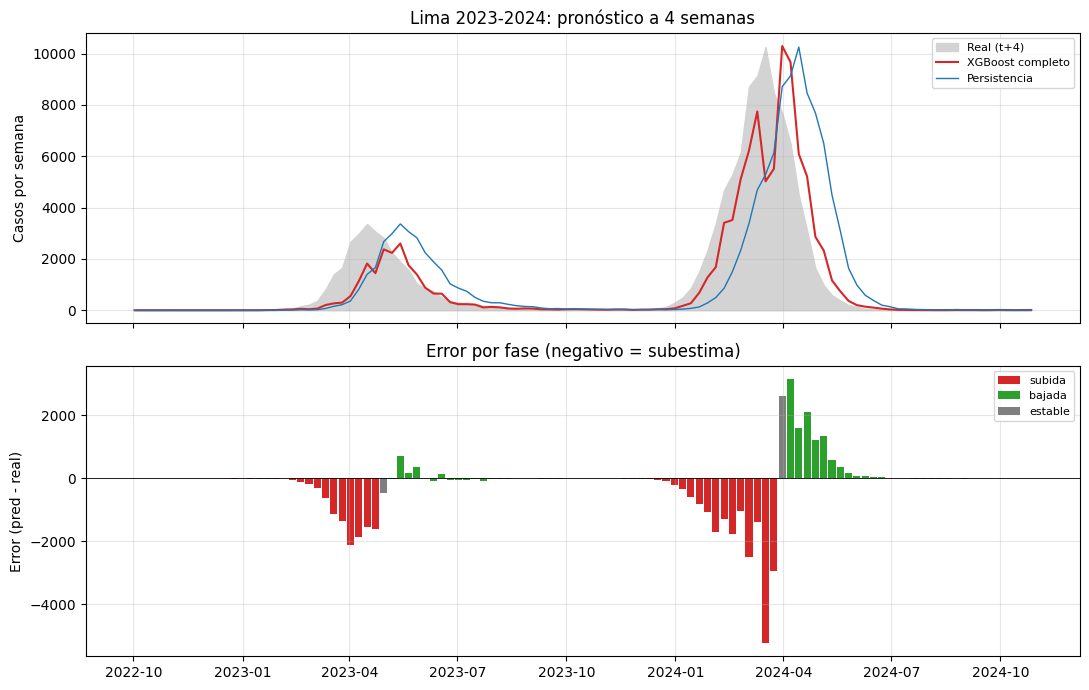

In [5]:
colores = {"subida": "tab:red", "bajada": "tab:green", "estable": "tab:gray"}
z = fechas >= "2022-10-01"
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].fill_between(fechas[z], real[z], color="lightgray", label="Real (t+4)")
ax[0].plot(fechas[z], completo[z], color="tab:red", lw=1.5, label="XGBoost completo")
ax[0].plot(fechas[z], pers[z], color="tab:blue", lw=1, label="Persistencia")
ax[0].set(ylabel="Casos por semana", title="Lima 2023-2024: pronóstico a 4 semanas"); ax[0].legend(fontsize=8)
for f, col in colores.items():
    s = z & (fase == f)
    ax[1].bar(fechas[s], (completo - real)[s], width=6, color=col, label=f)
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set(ylabel="Error (pred - real)", title="Error por fase (negativo = subestima)"); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(RESULTS / "plots" / "error_por_fase.png", dpi=150); plt.show()